In [17]:
import matplotlib.pyplot as plt

import astropy.units as u
import astropy.coordinates as coord
from astropy.table import Table

import galstreams
from gala.units import UnitSystem
usys = UnitSystem(u.kpc, u.Myr, u.Msun, u.radian)

import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp

import streamsculptor
import streamsculptor.JaxCoords as jc
from streamsculptor.potential import MW_LMC_Potential
# Intialization of this class takes a moment: 
# splines are fit on the fly for the MW and LMC (all with jit)
pot_MWLMC = MW_LMC_Potential(units=usys)

%config InlineBackend.figure_format = 'retina'

In [3]:
mwstreams = galstreams.MWStreams(implement_Off=True)

Initializing galstreams library from master_log... 


In [29]:
frame = mwstreams['AAU-ATLAS-L21'].stream_frame
galcen_frame = coord.Galactocentric(galcen_distance=8.275 * u.kpc, galcen_v_sun=[8.4, 251, 8.4] * u.km / u.s)

In [5]:
ts = Table.read('../data/all_streams_unique.fits')

In [6]:
ts

source_id,dist,dist_err,Vr,Vr_err,FeH,FeH_err,aFe,aFe_err,p_mem,ra,ra_error,dec,dec_error,parallax,parallax_error,parallax_over_error,pm,pmra,pmra_error,pmdec,pmdec_error,ra_dec_corr,ra_parallax_corr,ra_pmra_corr,ra_pmdec_corr,dec_parallax_corr,dec_pmra_corr,dec_pmdec_corr,parallax_pmra_corr,parallax_pmdec_corr,pmra_pmdec_corr,phot_g_mean_mag,bp_rp,name,reference,d_orb,X,Y,Z
,kpc,kpc,km / s,km / s,[-],[-],,,,deg,mas,deg,mas,mas,mas,,mas / yr,mas / yr,mas / yr,mas / yr,mas / yr,,,,,,,,,,,mag,mag,,,kpc,kpc,kpc,kpc
int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float32,float64,float32,float64,float32,float32,float32,float64,float32,float64,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,bytes15,bytes33,float64,float64,float64,float64
614929674862467712,--,--,--,--,--,--,--,--,--,150.33340244295138,0.2172744,13.24963486472028,0.18321106,-0.3381786908535966,0.25940955,-1.3036479,4.0808206,-2.911746254015053,0.27712572,-2.8591656877612537,0.20834441,-0.27213326,-0.2688552,-0.20517108,-0.04061675,0.122902796,-0.032932352,-0.46550173,0.36616457,-0.24776016,-0.472972,18.884916,0.73716545,300S,Ibata2024,16.79,-16.390325325962408,-7.739393979971578,12.513463357714752
615585464829093376,--,--,--,--,--,--,--,--,--,151.20306019519643,0.07055353,15.0644458030475,0.07045847,0.17911830305781481,0.094154194,1.9023932,3.823125,-2.6025168420229896,0.091028675,-2.8005695571293465,0.073981054,-0.40919924,-0.3131129,-0.403757,0.27107292,0.047583494,0.17083327,-0.6234429,0.6029098,-0.3358856,-0.5342571,17.023706,1.0926495,300S,Ibata2024,16.55,-16.278108557257383,-7.1296444539559305,12.62614225435744
615793203807403136,--,--,289.64,13.2,--,--,--,--,--,150.80093245391498,0.105187275,15.251068516606624,0.09548935,-0.16577688810328448,0.12822632,-1.292846,3.7855484,-2.5787482483325683,0.123326175,-2.771359639657288,0.09676449,-0.19381382,-0.17572111,-0.36642805,0.04986707,0.19347896,0.035219863,-0.6044907,0.44029,-0.37176982,-0.2608366,17.81228,1.0022182,300S,Ibata2024,16.70,-16.463191549384597,-7.165330457334928,12.692559950472583
616138592192425856,--,--,--,--,--,--,--,--,--,148.2127272990071,0.23687758,14.86371021955599,0.19594307,-0.33348462878182056,0.29002234,-1.1498584,3.5326731,-2.4460593020568853,0.29745242,-2.548837629445982,0.2266088,-0.29243183,-0.3753647,-0.3257198,0.14543423,0.13805312,0.18332621,-0.61194575,0.48853102,-0.24434897,-0.4707569,18.995935,0.8934612,300S,Ibata2024,17.71,-17.51526959286676,-7.80458414557209,12.950489276248849
616408792882903296,--,--,299.55,13.19,--,--,--,--,--,147.8030755962404,0.06578866,15.386929543937446,0.06529123,0.06397401246297103,0.074224725,0.8618963,3.4420931,-2.1418607404594425,0.08339962,-2.6945198915518356,0.072843075,-0.34804758,-0.15600641,-0.26102147,0.25778595,0.07285713,0.22747582,-0.7075626,0.3070973,-0.27311182,-0.39333603,16.937613,1.0856133,300S,Ibata2024,17.90,-17.771920921160238,-7.759902395201679,13.062272146604569
616546541071209856,--,--,297.79,5.46,--,--,--,--,--,149.20536284036064,0.0986222,15.367928462127727,0.07905106,-0.16422922891836406,0.109992206,-1.4930989,3.7338042,-2.6365814344498886,0.124232344,-2.6438103101322694,0.09245272,-0.18257877,-0.34422466,-0.35431823,-0.0060119964,0.1681687,-0.02229197,-0.5348794,0.32588485,-0.23508537,-0.3357986,17.57592,1.0496082,300S,Ibata2024,17.32,-17.14510131153485,-7.4638570758826415,12.891299330089161
616609080089944576,--,--,--,--,--,--,--,--,--,150.26720855332013,0.056437943,15.558842935435527,0.058013845,-0.019354280188253834,0.067573845,-0.28641674,3.7514875,-2.526472465501137,0.071697935,-2.7731921271706605,0.07131226,-0.44335383,-0.22080313,-0.23138522,0.17367893,0.128595,0.275731,-0.59745723,0.3152447,-0.1369898,-0.604067,16.595741,1.0973196,300S,Ibata2024,16.92,-16.721147807086847,-7.198014389807759,12.7884518530784
616627252096354304,--,--,--,--,--,--,--,--,--,150.0068668733642,0.40243876,15.731172435914717,0.3405932,-0.5598713922195149,

In [7]:
stream = 'ATLAS-Aliqa Uma'

In [8]:
taau = ts[ts['name']==stream]

In [9]:
taau

source_id,dist,dist_err,Vr,Vr_err,FeH,FeH_err,aFe,aFe_err,p_mem,ra,ra_error,dec,dec_error,parallax,parallax_error,parallax_over_error,pm,pmra,pmra_error,pmdec,pmdec_error,ra_dec_corr,ra_parallax_corr,ra_pmra_corr,ra_pmdec_corr,dec_parallax_corr,dec_pmra_corr,dec_pmdec_corr,parallax_pmra_corr,parallax_pmdec_corr,pmra_pmdec_corr,phot_g_mean_mag,bp_rp,name,reference,d_orb,X,Y,Z
,kpc,kpc,km / s,km / s,[-],[-],,,,deg,mas,deg,mas,mas,mas,,mas / yr,mas / yr,mas / yr,mas / yr,mas / yr,,,,,,,,,,,mag,mag,,,kpc,kpc,kpc,kpc
int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float32,float64,float32,float64,float32,float32,float32,float64,float32,float64,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,bytes15,bytes33,float64,float64,float64,float64
5039838702437479936,--,--,-113.36,0.22,--,--,--,--,--,19.112903636805836,0.03027964,-26.11693093044752,0.01838506,0.032045493116992826,0.041180976,0.77816254,0.9545712,-0.10363643781858604,0.0456984,-0.9489286998696127,0.024278957,0.08598094,0.10642476,-0.18841869,-0.15589535,0.04124403,-0.107682586,-0.31326038,0.4667607,-0.08492495,-0.12818016,15.572575,1.1649532,ATLAS-Aliqa Uma,"Ibata2024, Li2021",20.30,-10.159765595471448,-0.8200075823042887,-20.172082369465194
5034653611759500160,--,--,-117.1,0.44,--,--,--,--,--,18.135219195158808,0.05608404,-25.865839070770907,0.03287621,0.056294530120900826,0.07589459,0.7417463,1.0479665,-0.20724121418500902,0.08962911,-1.0272706261134024,0.042653807,0.035356842,-0.08234328,-0.359956,-0.11127108,0.07533983,-0.07608048,-0.42228067,0.5120982,-0.18434899,-0.2875143,16.8478,1.0383053,ATLAS-Aliqa Uma,"Ibata2024, Li2021",20.09,-9.941628741892476,-0.5612983786960237,-19.987564864667448
5022844307121290752,--,--,-86.36,0.48,--,--,--,--,--,25.03612906558231,0.019145278,-29.870711467466965,0.01422518,0.004926049222016969,0.02530675,0.19465357,0.9380456,0.054283998283948615,0.029626494,-0.936473600999103,0.016412068,0.0719732,0.014703146,0.07709524,0.0037034934,0.05069902,-0.020186407,0.2497003,0.30388278,-0.11838507,-0.18870658,14.948317,1.2818184,ATLAS-Aliqa Uma,"Ibata2024, Li2021",22.02,-11.030273705475334,-3.2380694544279693,-21.583750145211063
4966915105554905344,--,--,-23.28,0.69,-2.13,0.11,--,--,--,36.609162859183506,0.014669121,-35.37392597307872,0.019442746,-0.023736301974611386,0.026026746,-0.91199654,0.78473276,0.3194157683873357,0.017006975,-0.716783850831943,0.026707526,-0.31035042,0.05764019,0.05250792,-0.06445052,0.028035676,-0.07570131,0.202657,0.06896887,-0.056221936,-0.39517376,15.4318695,1.2874537,ATLAS-Aliqa Uma,"Li2021, Shipp2019",25.71,-12.976169383269035,-8.363406494158884,-23.829538451071247
4971176778264340352,--,--,-52.38,0.7,-2.22,0.11,--,--,--,32.28456434900104,0.018097239,-32.76836942329286,0.020554995,-0.002557144194328991,0.02949158,-0.08670761,0.8681954,0.1548694399320265,0.01844903,-0.8542708991607908,0.02786216,-0.018028716,0.16067058,0.6596012,-0.08222104,-0.16633834,-0.09410137,-0.1441438,0.23105629,0.026856575,0.00022166136,15.379307,1.2533436,ATLAS-Aliqa Uma,"Li2021, Ibata2024",24.17,-12.427414230550017,-6.110573880778404,-22.990599454964606
2345957664457105408,--,--,-130.80131456567318,0.7352161004647121,-2.5114520210228495,0.03497776297230554,--,--,0.92,14.666996194977685,0.034284763,-23.863799237542633,0.023963924,0.07172146393966614,0.051698565,1.3873008,1.0951513,-0.3734812765422289,0.051487472,-1.0294989491315438,0.05026018,0.3889798,0.33991417,-0.049457468,0.09017925,0.29025984,0.168421,0.5170012,0.2708115,-0.11290532,0.2210949,15.542069,1.1481123,ATLAS-Aliqa Uma,"Shipp2019, Ibata2024, Li2021",19.24,-9.382202952152944,0.6143870053010447,-19.17289282073603
5018003535381679488,--,--,-63.35,0.75,-2.28,0.13,--,--,--,29.55297381449389,0.026449822,-32.49086663268327,0.028780432,0.05530732303988214,0.041682016,1.326887,0.8749636,0.17602608752355914,0.027122078,-0.857074124209692,0.037284978,-0.08969228,0.18131171,0.68254644,-0.22601801,-0.02

In [10]:
# rename columns:
col_rename = ['dist', 'Vr', 'FeH', 'aFe']
for k in col_rename:
    taau.rename_column(f'{k:s}_err', f'{k:s}_error')

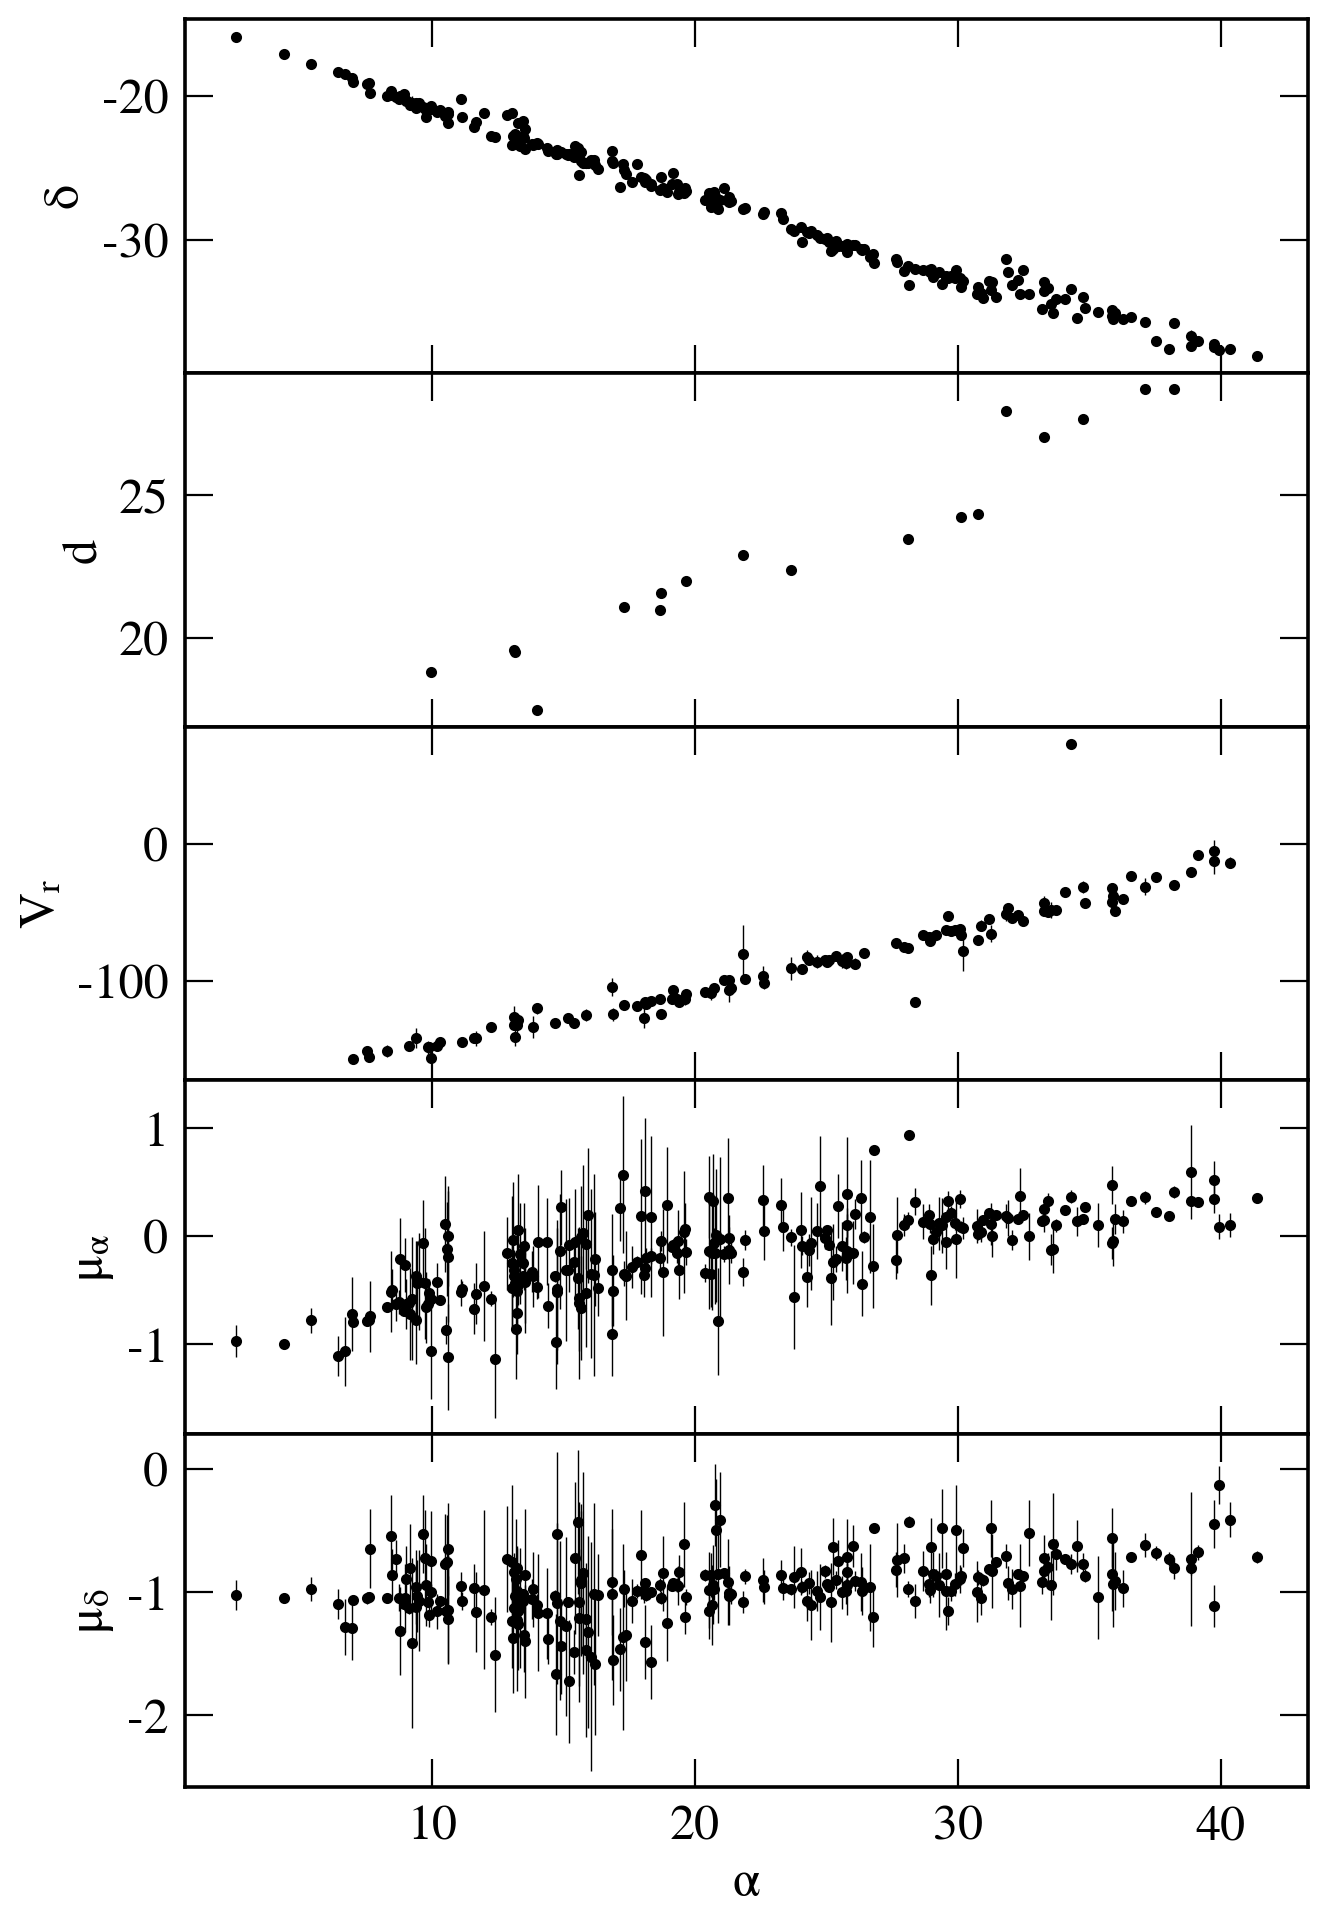

In [18]:
fig, ax = plt.subplots(5,1,figsize=(7,10), sharex=True)

ylist = ['dec', 'dist', 'Vr', 'pmra', 'pmdec']
ylabels = ['$\\delta$', 'd', '$V_r$', '$\\mu_\\alpha$', '$\\mu_\\delta$']

for i in range(5):
    plt.sca(ax[i])
    plt.errorbar(taau['ra'], taau[ylist[i]], yerr=taau[f'{ylist[i]:s}_error'], fmt='o', ms=3, lw=0.5, color='k')
    plt.ylabel(ylabels[i])

plt.xlabel('$\\alpha$')
plt.tight_layout(h_pad=0)
    

In [13]:
ceq = coord.SkyCoord(ra=taau['ra'], dec=taau['dec'], distance=taau['dist'], pm_ra_cosdec=taau['pmra'], pm_dec=taau['pmdec'],
                     radial_velocity=taau['Vr'], frame='icrs')
cs = ceq.transform_to(frame)

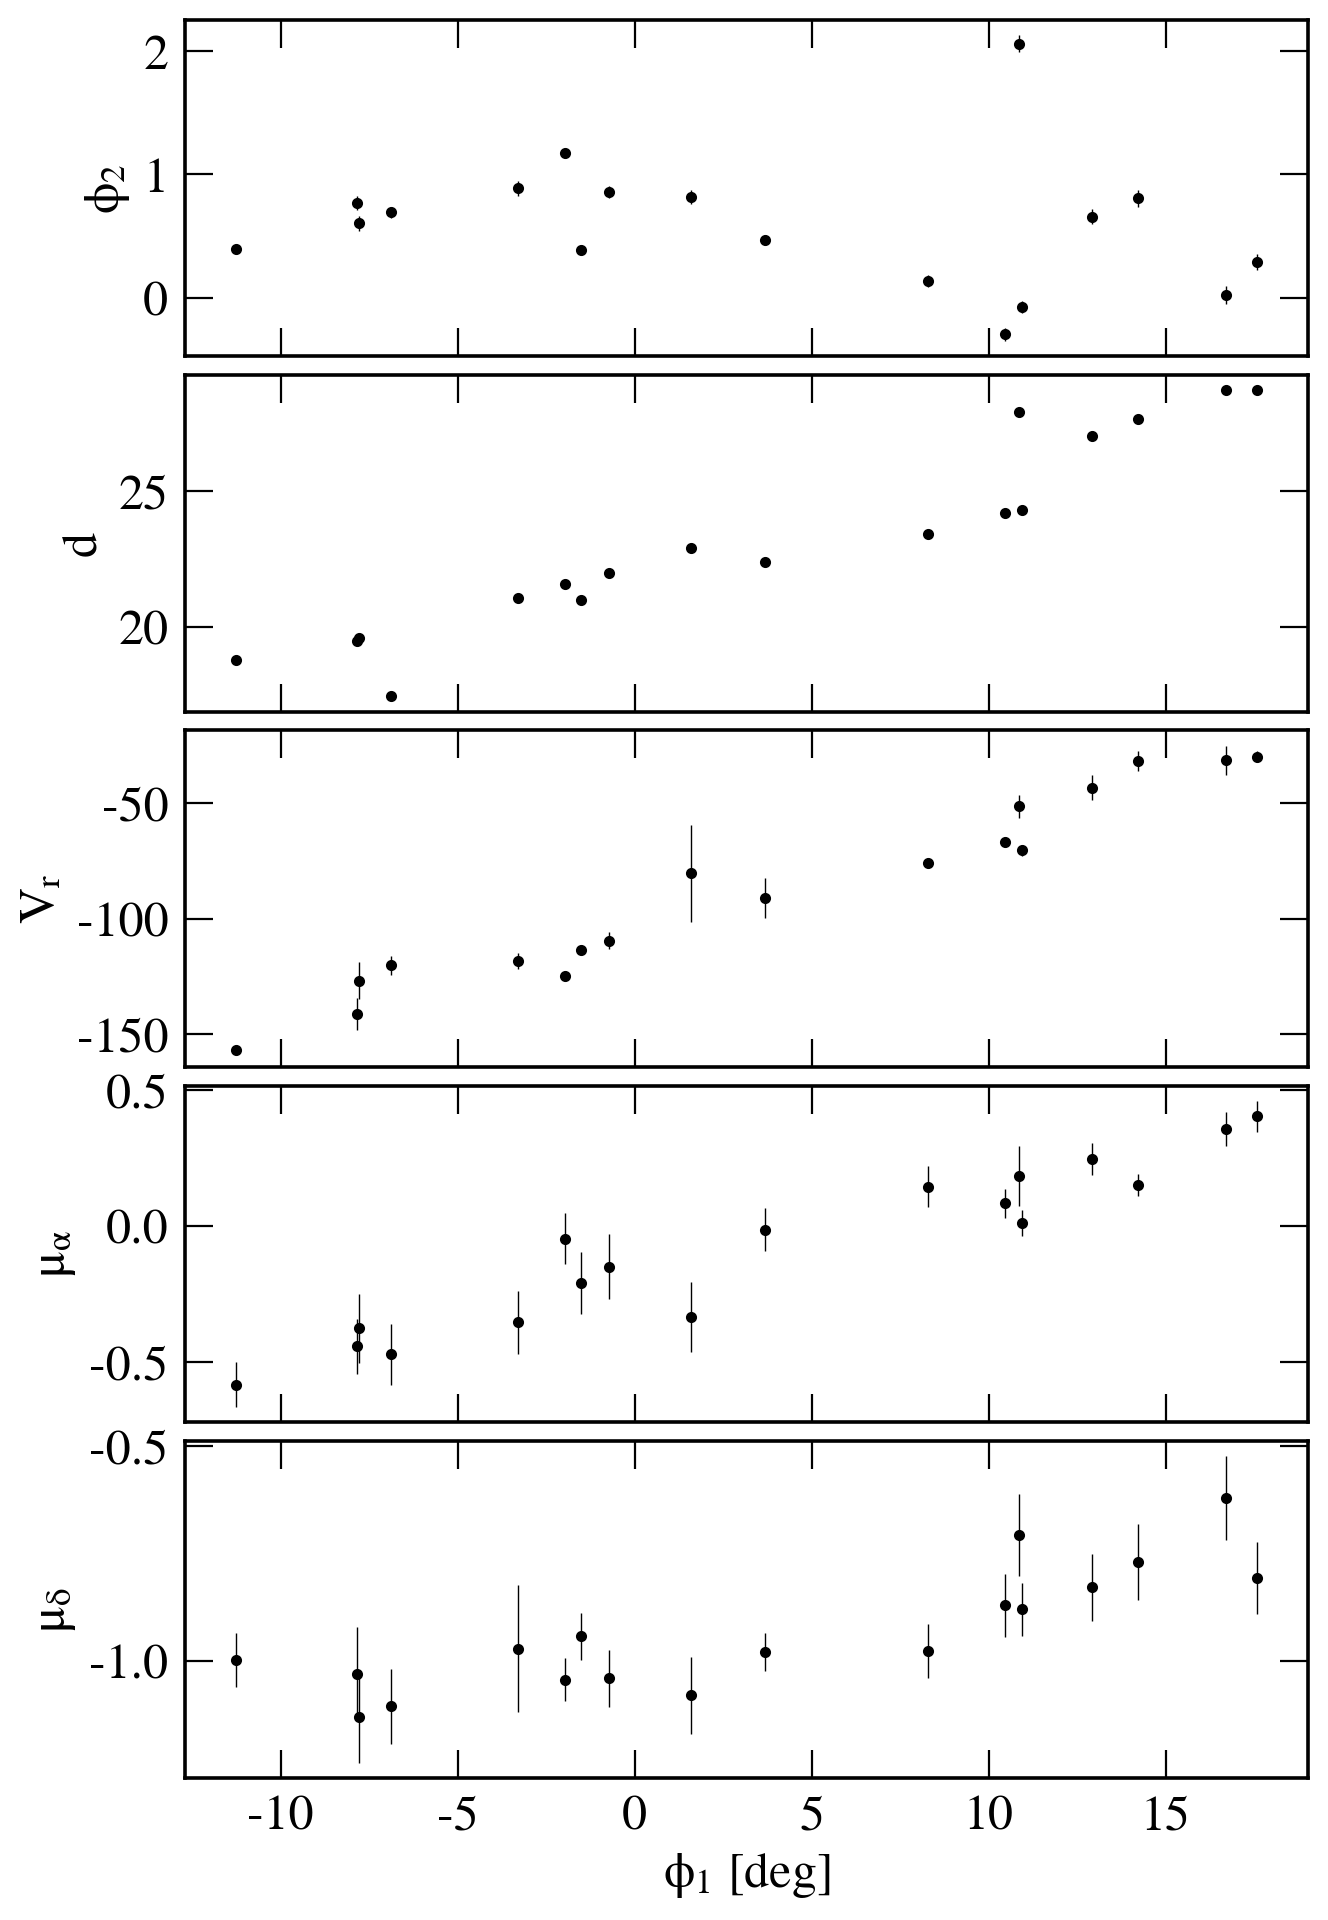

In [23]:
fig, ax = plt.subplots(5,1,figsize=(7,10), sharex=True)

ylist = ['dec', 'dist', 'Vr', 'pmra', 'pmdec']
yplot = [cs.phi2.value] + [taau[yl] for yl in ylist[1:]]
ylabels = ['$\phi_2$', 'd', '$V_r$', '$\\mu_\\alpha$', '$\\mu_\\delta$']

for i in range(5):
    plt.sca(ax[i])
    plt.errorbar(cs.phi1, yplot[i], yerr=taau[f'{ylist[i]:s}_error'], fmt='o', ms=3, lw=0.5, color='k')
    plt.ylabel(ylabels[i])

plt.xlabel('$\phi_1$ [deg]')
plt.tight_layout(h_pad=0)
    

### Trial progenitor location

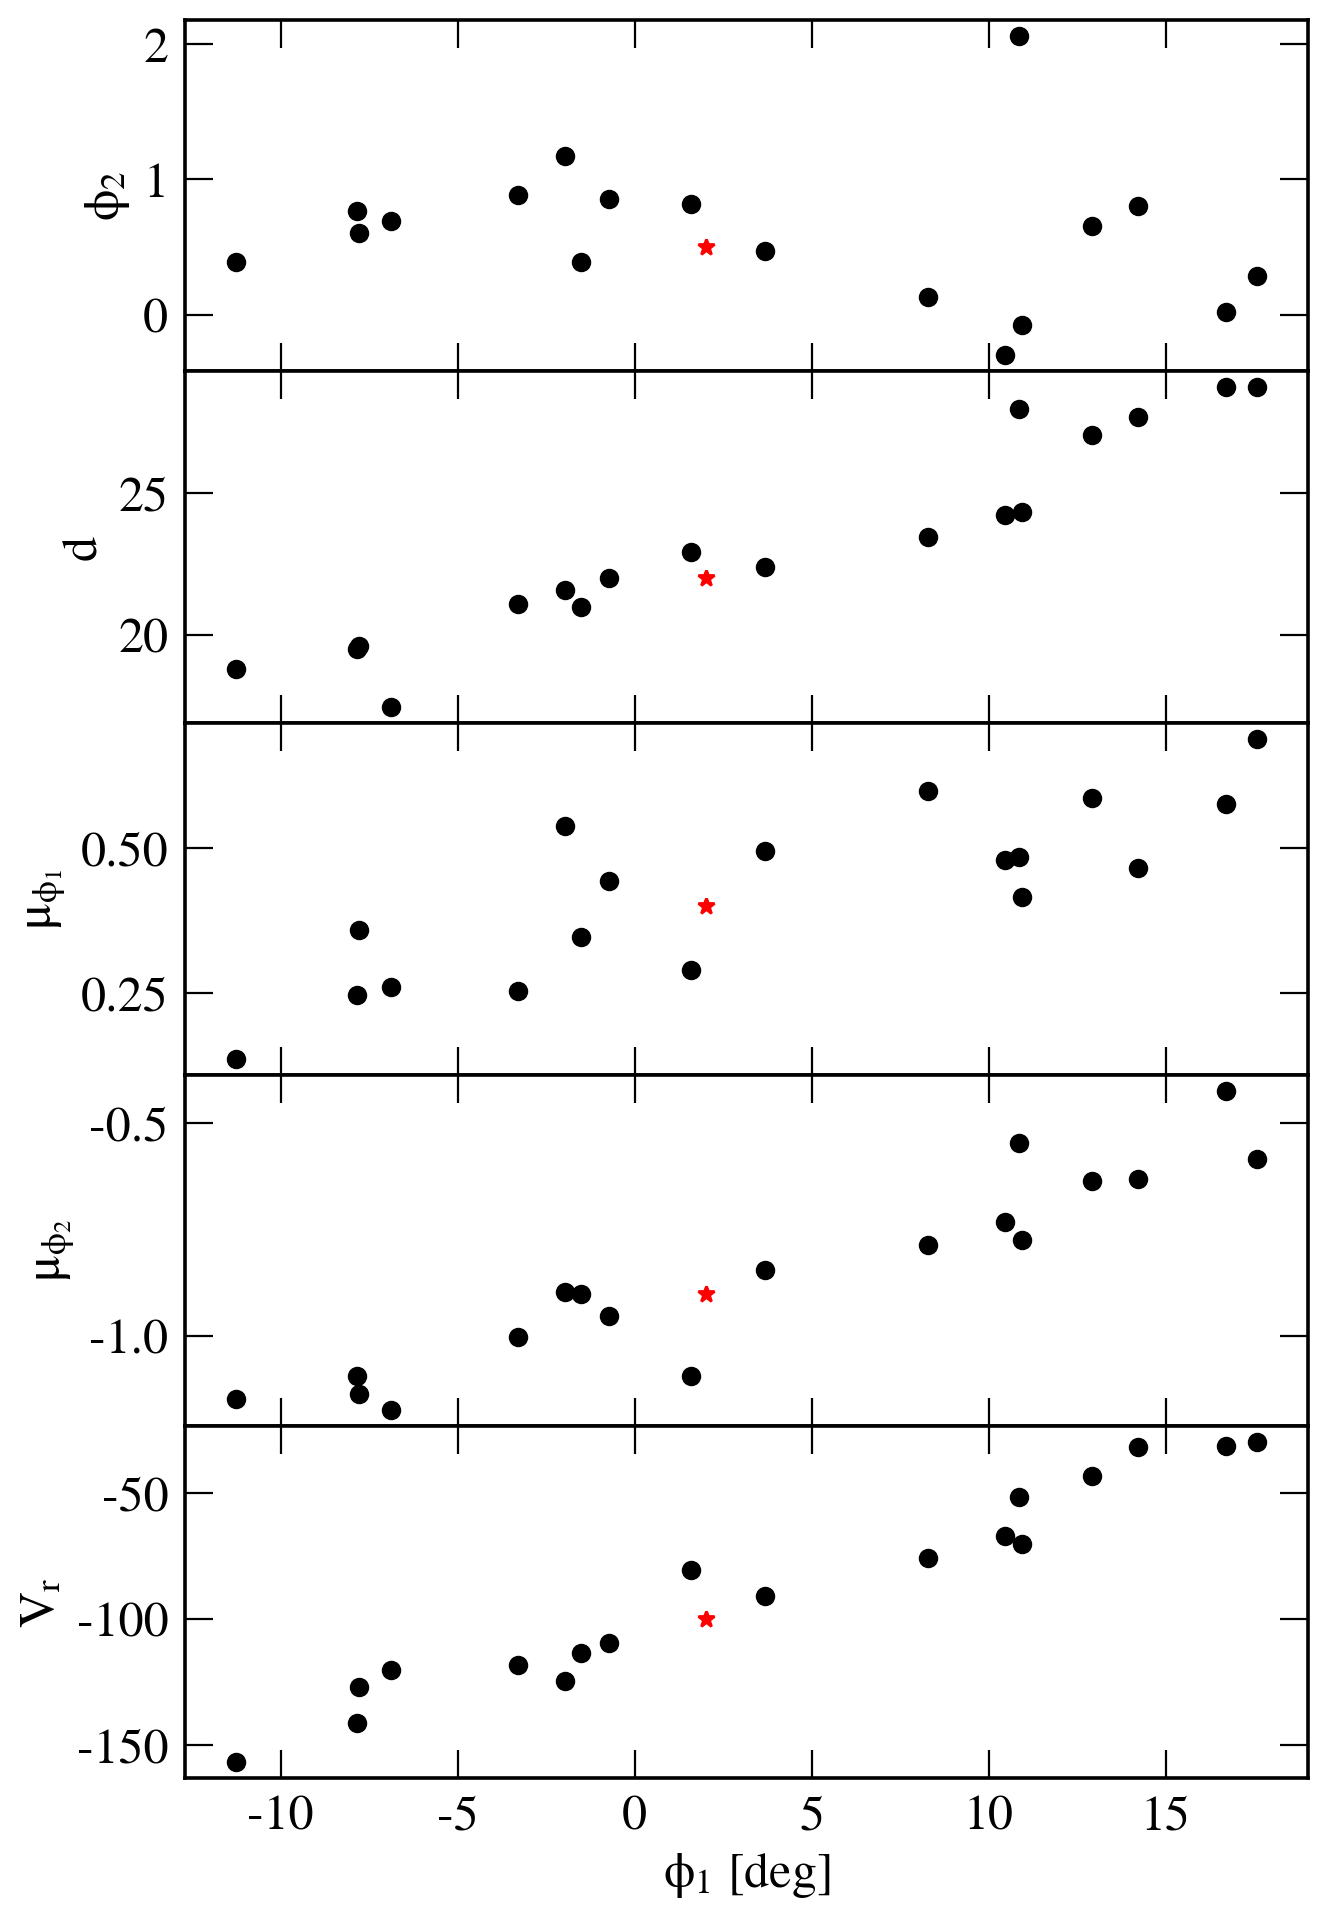

In [54]:
cs_prog = coord.SkyCoord(phi1=2*u.deg, phi2=0.5*u.deg, distance=22*u.kpc, pm_phi1_cosphi2=0.4*u.mas/u.yr, pm_phi2=-0.9*u.mas/u.yr, radial_velocity=-100*u.km/u.s,
                        frame=frame)

fig, ax = plt.subplots(5,1,figsize=(7,10), sharex=True)

yplot = [cs.phi2, cs.distance, cs.pm_phi1_cosphi2, cs.pm_phi2, cs.radial_velocity]
yplot_prog = [cs_prog.phi2, cs_prog.distance, cs_prog.pm_phi1_cosphi2, cs_prog.pm_phi2, cs_prog.radial_velocity]
ylabels = ['$\phi_2$', 'd', '$\\mu_{\phi_1}$', '$\\mu_{\phi_2}$', '$V_r$']

for i in range(5):
    plt.sca(ax[i])
    plt.plot(cs.phi1, yplot[i], 'ko')
    plt.plot(cs_prog.phi1, yplot_prog[i], 'r*')
    plt.ylabel(ylabels[i])

plt.xlabel('$\phi_1$ [deg]')
plt.tight_layout(h_pad=0)


In [66]:
# create present-day position for the progenitor
cgal_prog = cs_prog.transform_to(coord.Galactocentric())

# jax arrays
q_prog = jnp.hstack([cgal_prog.x.to(u.kpc).value, cgal_prog.y.to(u.kpc).value, cgal_prog.z.to(u.kpc).value])
p_prog = jnp.hstack([cgal_prog.v_x.to(u.kpc/u.Myr).value, cgal_prog.v_y.to(u.kpc/u.Myr).value, cgal_prog.v_z.to(u.kpc/u.Myr).value])

prog_wf = jnp.hstack([q_prog, p_prog])

In [67]:
# In MW-LMC potential integrate back, and then generate stream forward
tback = -2000.0
Init_Cond = pot_MWLMC.integrate_orbit(w0=prog_wf, t0=0.0, t1=tback, ts=jnp.array([tback])).ys[0]

In [79]:
# Define stripping times for stream
ts = jnp.hstack([jnp.linspace(tback,-10,1_000),jnp.array([0.0])])

# generate stream model
stream_lead, stream_trail = pot_MWLMC.gen_stream_scan(prog_w0=Init_Cond, ts=ts, Msat=3e4, seed_num=42)
stream_MWLMC = jnp.vstack([stream_lead, stream_trail])

In [80]:
# coordinate objects for the stream
cgal_stream = coord.Galactocentric(x=stream_MWLMC[:,0]*u.kpc, y=stream_MWLMC[:,1]*u.kpc, z=stream_MWLMC[:,2]*u.kpc,
                                  v_x=stream_MWLMC[:,3]*u.kpc/u.Myr, v_y=stream_MWLMC[:,4]*u.kpc/u.Myr, v_z=stream_MWLMC[:,5]*u.kpc/u.Myr)
cs_stream = cgal_stream.transform_to(frame)

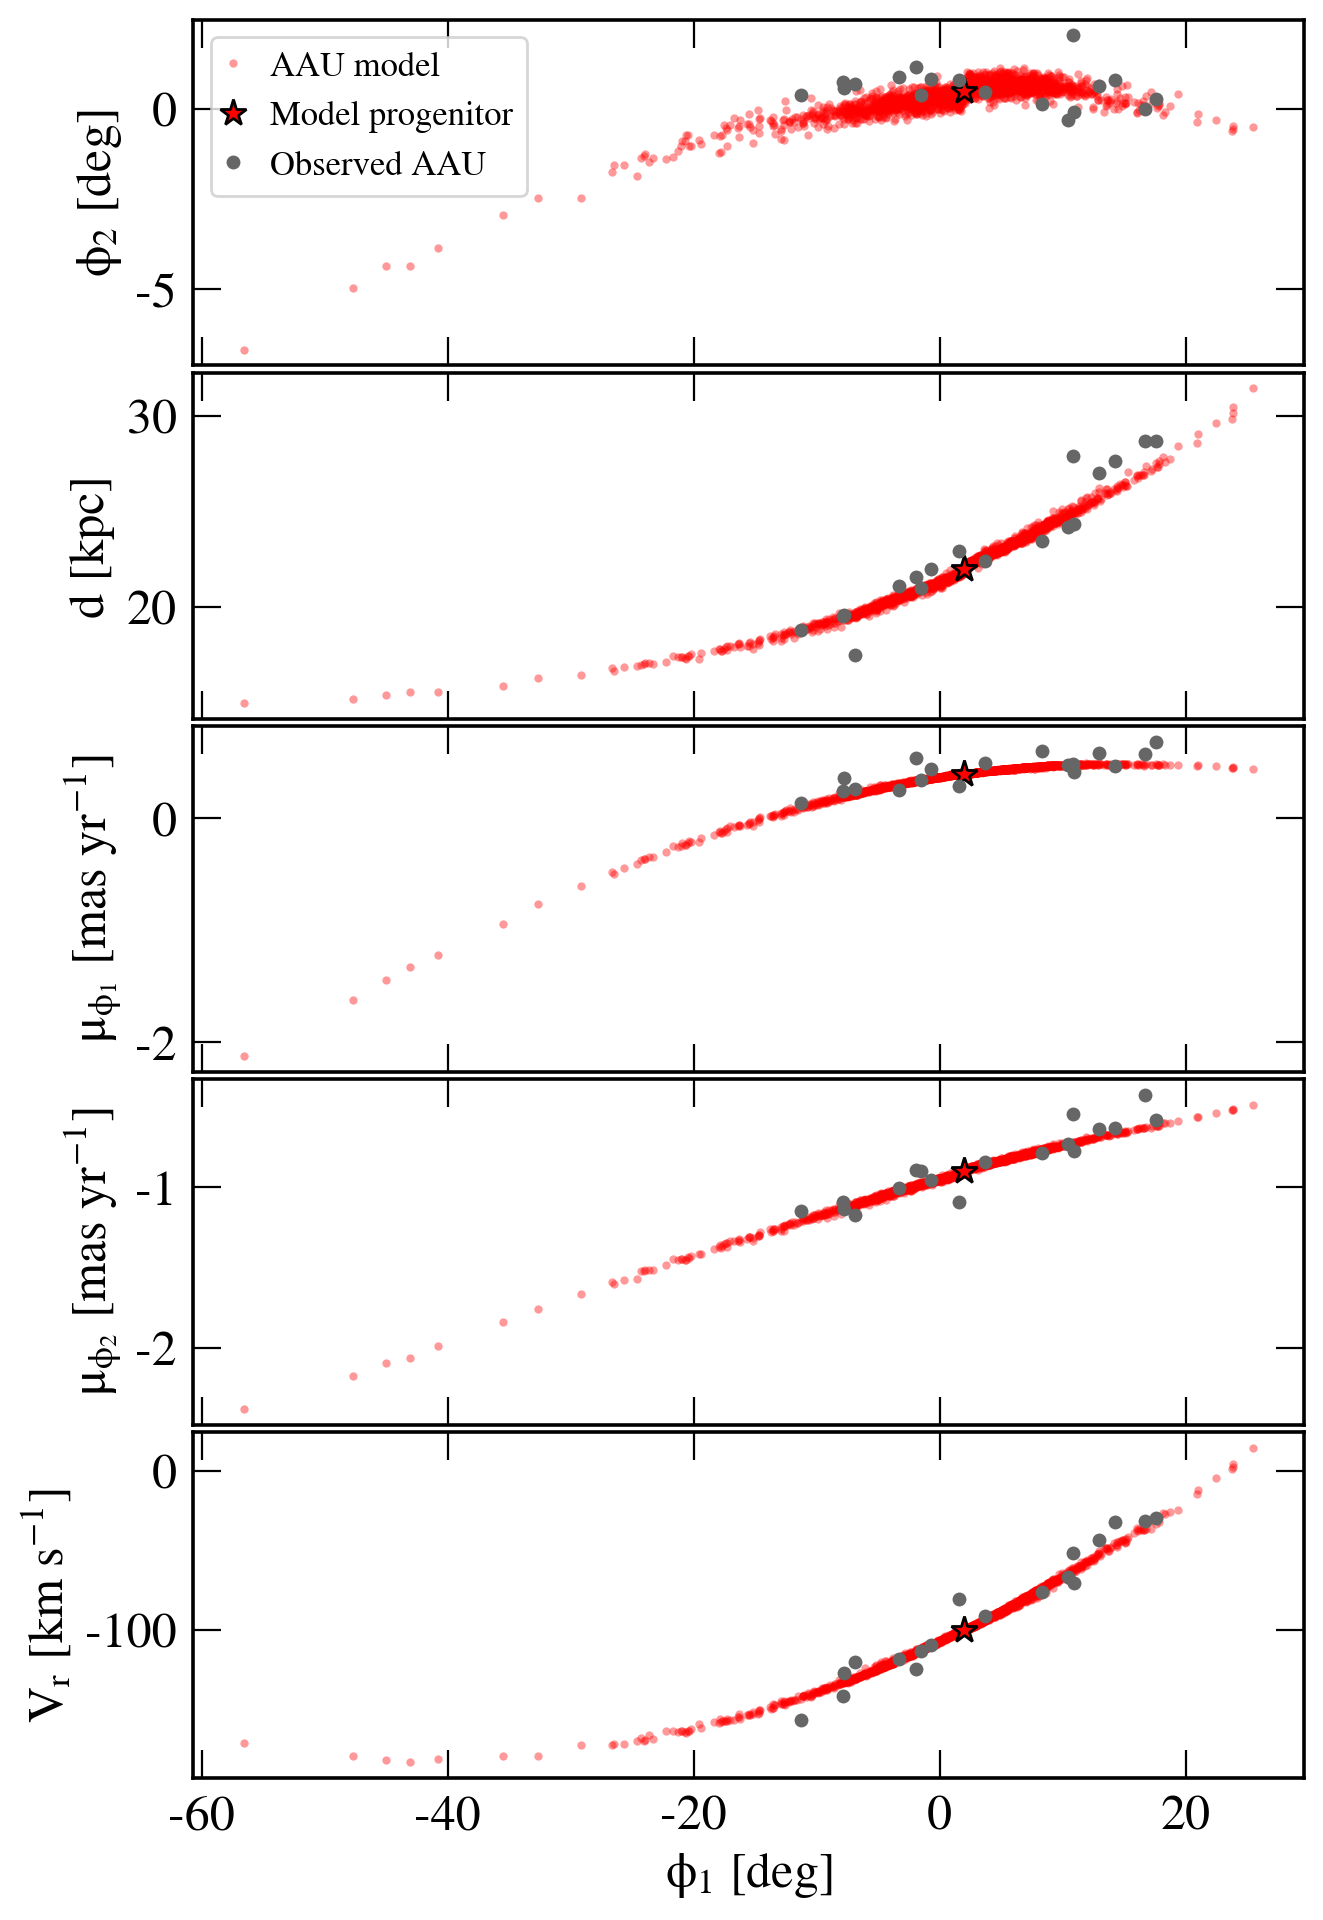

In [81]:
# compare model and observed stream
fig, ax = plt.subplots(5,1,figsize=(7,10), sharex=True)

yplot = [cs.phi2, cs.distance, cs.pm_phi1_cosphi2, cs.pm_phi2, cs.radial_velocity]
yplot_prog = [cs_prog.phi2, cs_prog.distance, cs_prog.pm_phi1_cosphi2, cs_prog.pm_phi2, cs_prog.radial_velocity]
yplot_stream = [cs_stream.phi2, cs_stream.distance, cs_stream.pm_phi1_cosphi2, cs_stream.pm_phi2, cs_stream.radial_velocity]

ylabels = ['$\phi_2$ [deg]', 'd [kpc]', '$\\mu_{\phi_1}$ [mas yr$^{-1}$]', '$\\mu_{\phi_2}$ [mas yr$^{-1}$]', '$V_r$ [km s$^{-1}$]']

for i in range(5):
    plt.sca(ax[i])
    
    plt.plot(cs_stream.phi1, yplot_stream[i], 'r.', mew=0, alpha=0.4, label='AAU model')
    plt.plot(cs_prog.phi1, yplot_prog[i], 'r*', mec='k', ms=10, label='Model progenitor')
    plt.plot(cs.phi1, yplot[i], 'o', mew=0, ms=5, color='0.4', label='Observed AAU')
    
    plt.ylabel(ylabels[i])

plt.xlabel('$\phi_1$ [deg]')
plt.sca(ax[0])
plt.legend(loc=2, fontsize='x-small', handlelength=0.5)
plt.tight_layout(h_pad=0)
